<a href="https://colab.research.google.com/github/Thrisha213/4NI25CS213_DAV_LAB/blob/main/4NI25CS213_EXP_09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Shape: (150, 6)
Missing Values: 0
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64
Accuracy: 1.0
Confusion Matrix:
 [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]
Classification Report:                  precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00         9
 Iris-virginica       1.00      1.00      1.00        11

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



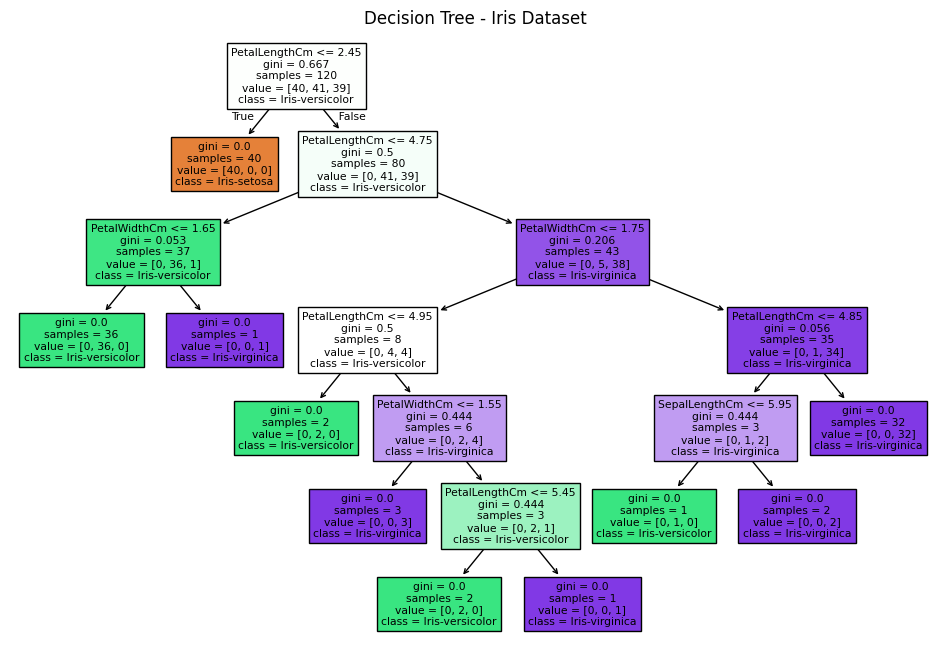

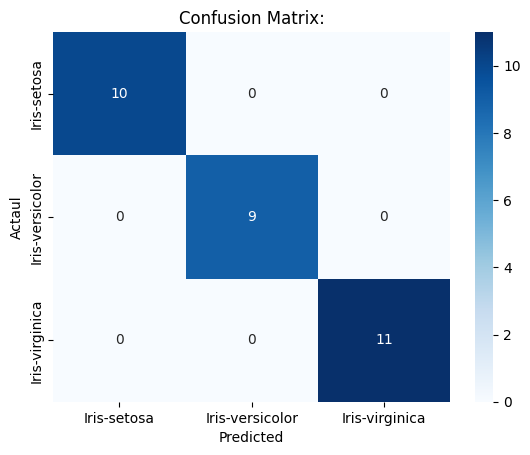

Feature Importance:
PetalLengthCm    0.906143
PetalWidthCm     0.077186
SepalLengthCm    0.016670
SepalWidthCm     0.000000
dtype: float64


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df = pd.read_csv('/content/Iris.csv')
print('Shape:', df.shape)
print('Missing Values:', df.isnull().sum().sum())
print(df['Species'].value_counts())
features = [col for col in df.columns if col not in ['Id', 'Species']]
X = df[features]
y = df['Species']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = DecisionTreeClassifier()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print('Accuracy:', accuracy_score(y_test, y_pred))
cm=confusion_matrix(y_test,y_pred)
print('Confusion Matrix:\n', cm)
print('Classification Report:',classification_report(y_test,y_pred))
plt.figure(figsize=(12,8))
plot_tree(model, filled=True, feature_names=features, class_names=y.unique())
plt.title('Decision Tree - Iris Dataset')
plt.show()
sns.heatmap(cm,annot=True,fmt='d',cmap="Blues",xticklabels=model.classes_,yticklabels=model.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actaul')
plt.title('Confusion Matrix:')
plt.show()
print('Feature Importance:')
print(pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False))